<a href="https://colab.research.google.com/github/yasasbanukaofficial/uber-fare-prediction/blob/main/uber_fare_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Uber Fare Prediction

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

## 1. Understand the Dataset

In [19]:
df = pd.read_csv("https://raw.githubusercontent.com/yasasbanukaofficial/uber-fare-prediction/refs/heads/main/uber.csv")
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB


In [21]:
df.describe()

,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,2.000000e+05,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,2.771250e+07,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,1.601382e+07,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382535e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774550e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155530e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


In [22]:
df.isnull().sum()

,0
Unnamed: 0,0
key,0
fare_amount,0
pickup_datetime,0
pickup_longitude,0
pickup_latitude,0
dropoff_longitude,1
dropoff_latitude,1
passenger_count,0


## 2. Data Cleaning and Feature Engineering

In [23]:
df = df.drop(columns=["Unnamed: 0", "key"])
df = df.dropna()

df = df[
    (df["pickup_longitude"].between(-74.3, -73.7)) &
    (df["dropoff_longitude"].between(-74.3, -73.7)) &
    (df["pickup_latitude"].between(40.5, 41.0)) &
    (df["dropoff_latitude"].between(40.5, 41.0)) &
    (df["passenger_count"].between(1, 6)) &
    (df["fare_amount"].between(2.5, 200))
]

In [24]:
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

df["distance_km"] = haversine(
    df["pickup_latitude"], df["pickup_longitude"],
    df["dropoff_latitude"], df["dropoff_longitude"]
)

dt = pd.to_datetime(df["pickup_datetime"])
df["hour"] = dt.dt.hour
df["day"] = dt.dt.day
df["month"] = dt.dt.month
df["year"] = dt.dt.year
df["day_of_week"] = dt.dt.dayofweek

df = df[df["distance_km"] > 0]
df = df.drop(columns=["pickup_datetime"])
df.head()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,distance_km,hour,day,month,year,day_of_week
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,1.683323,19,7,5,2015,3
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,2.457590,20,17,7,2009,4
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,5.036377,21,24,8,2009,0
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,1.661683,8,26,6,2009,4
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,4.475450,17,28,8,2014,3


## 3. Exploratory Data Analysis

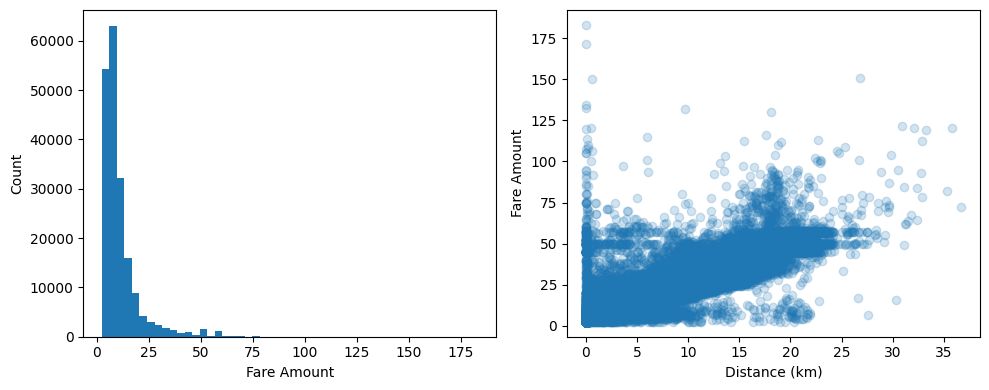

In [25]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.hist(df["fare_amount"], bins=50)
plt.xlabel("Fare Amount")
plt.ylabel("Count")

plt.subplot(1, 2, 2)
plt.scatter(df["distance_km"], df["fare_amount"], alpha=0.2)
plt.xlabel("Distance (km)")
plt.ylabel("Fare Amount")
plt.tight_layout()
plt.show()

In [26]:
df.corr()["fare_amount"].sort_values(ascending=False)

,fare_amount
fare_amount,1.000000
distance_km,0.881243
pickup_longitude,0.429706
dropoff_longitude,0.307816
year,0.122642
month,0.024499
passenger_count,0.013082
day_of_week,0.005260
day,0.000402
hour,-0.020202


## 4. Train Test Split

In [27]:
X = df.drop(columns=["fare_amount"])
y = df["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## 5. Model Building

In [28]:
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

In [29]:
poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

poly_reg = LinearRegression()
poly_reg.fit(X_train_poly, y_train)
y_pred_poly = poly_reg.predict(X_test_poly)

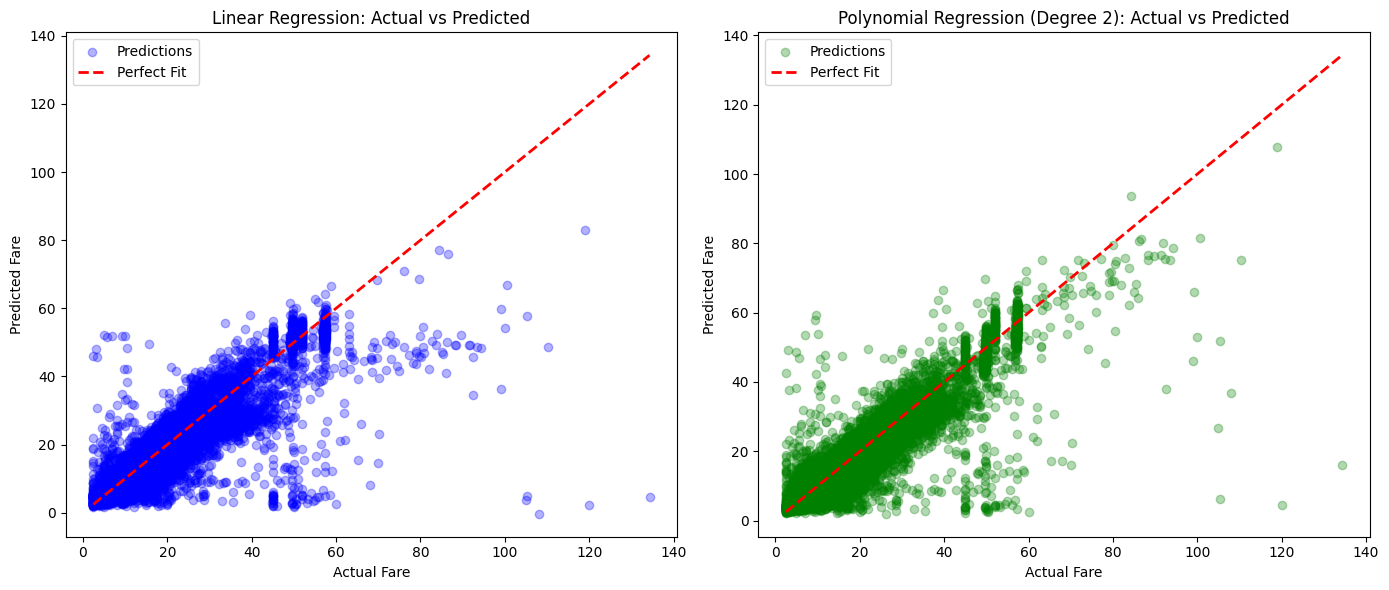

In [30]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred_lr, alpha=0.3, color='blue', label='Predictions')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Fit')
plt.title('Linear Regression: Actual vs Predicted')
plt.xlabel('Actual Fare')
plt.ylabel('Predicted Fare')
plt.legend()

plt.subplot(1, 2, 2)
plt.scatter(y_test, y_pred_poly, alpha=0.3, color='green', label='Predictions')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Fit')
plt.title('Polynomial Regression (Degree 2): Actual vs Predicted')
plt.xlabel('Actual Fare')
plt.ylabel('Predicted Fare')
plt.legend()

plt.tight_layout()
plt.show()

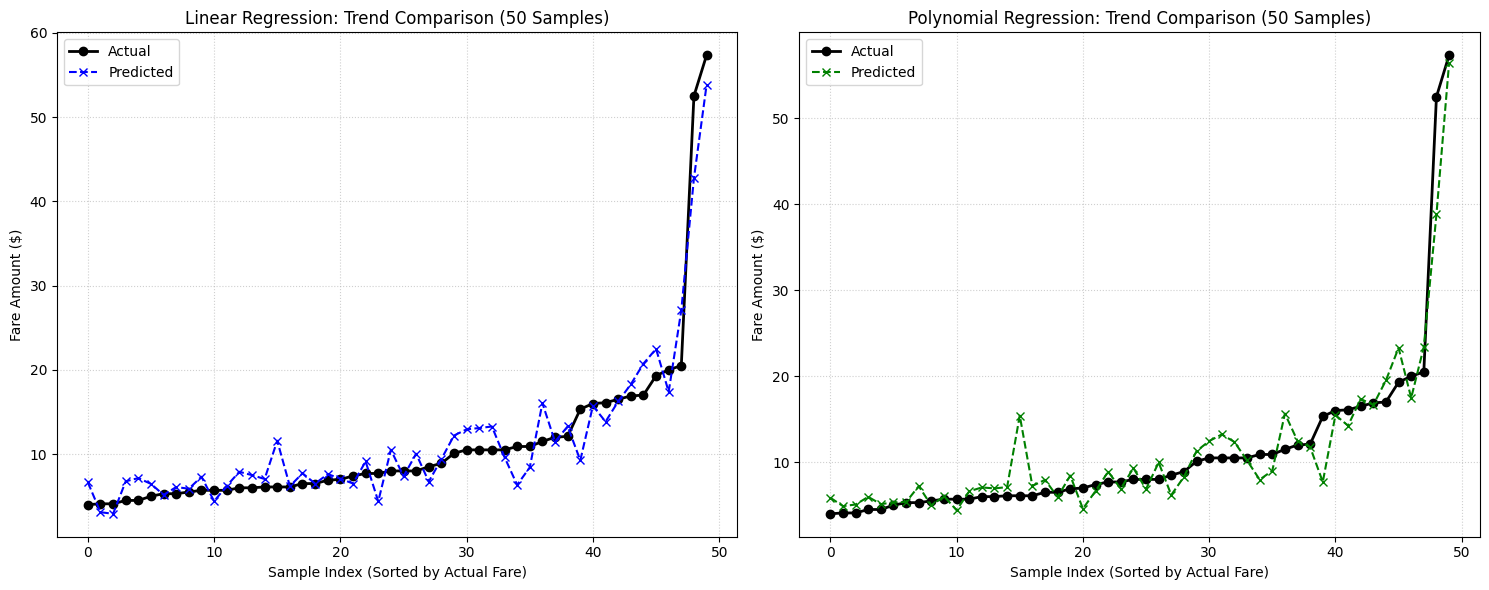

In [31]:
plot_df = pd.DataFrame({
    'Actual': y_test,
    'Linear Regression': y_pred_lr,
    'Polynomial Regression': y_pred_poly
}).sample(n=50, random_state=42).sort_values(by='Actual').reset_index(drop=True)

plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
plt.plot(plot_df['Actual'], label='Actual', marker='o', color='black', linewidth=2)
plt.plot(plot_df['Linear Regression'], label='Predicted', marker='x', linestyle='--', color='blue', linewidth=1.5)
plt.title('Linear Regression: Trend Comparison (50 Samples)')
plt.xlabel('Sample Index (Sorted by Actual Fare)')
plt.ylabel('Fare Amount ($)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

plt.subplot(1, 2, 2)
plt.plot(plot_df['Actual'], label='Actual', marker='o', color='black', linewidth=2)
plt.plot(plot_df['Polynomial Regression'], label='Predicted', marker='x', linestyle='--', color='green', linewidth=1.5)
plt.title('Polynomial Regression: Trend Comparison (50 Samples)')
plt.xlabel('Sample Index (Sorted by Actual Fare)')
plt.ylabel('Fare Amount ($)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

## 6. Model Evaluation and Comparison

In [32]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Polynomial Regression (Degree 2)"],
    "R2 Score": [r2_score(y_test, y_pred_lr), r2_score(y_test, y_pred_poly)],
    "RMSE": [np.sqrt(mean_squared_error(y_test, y_pred_lr)), np.sqrt(mean_squared_error(y_test, y_pred_poly))]
})
results

,Model,R2 Score,RMSE
0,Linear Regression,0.801595,4.232639
1,Polynomial Regression (Degree 2),0.837988,3.824791
